# Lab notebook: HW9 data pipeline, first analysis

**Bianca Alexis · PHYS 7440**

**Question.** Does the Chen et al. (2019) p-derived tilt estimator recover the true tilt of the mean
magnetic field better than my Week 8 prior-only baseline (a constant guess of 30°), on (1) a CATS
Cho-ENO run (`b.1p.01_t750`, strongly super-Alfvénic) and (2) my own Athena++ box (sub-Alfvénic)?

**How to use this notebook.** Run the pipeline first:

```
python data_pipeline_alexis.py --fetch --force --build --verify --all
```

then *Kernel → Restart & Run All*. Everything below is read from the pipeline's SQLite cache and
`provenance_alexis.json`; nothing is typed in by hand. The numbers shown are whatever your run produced.

In [1]:
import json, os, sys, sqlite3
from IPython.display import display
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path(os.environ.get("PROJECT", ".")).resolve()
sys.path.insert(0, str(PROJECT))
import data_pipeline_alexis as pl
from evaluate import grade                     # my pre-registered grading rule (Week 8)

PROV = json.loads((PROJECT / "provenance_alexis.json").read_text())
DB = PROJECT / "cache" / "pipeline_cache_alexis.db"
CATS_ID, CATS_LEGACY = "cho:b.1p.01:t750", "b.1p.01_t750"
ATHENA_ID = next((k for k in PROV["datasets"] if k.startswith("athenapp:")), None)
pd.set_option("display.width", 140, "display.max_colwidth", 60)
print("project:", PROJECT)
print("datasets in provenance:", list(PROV["datasets"]))

project: /Users/BiancaAlexis/Desktop/Athena__November/hw9
datasets in provenance: ['athenapp:1395e2f:Turb.out2.00050', 'cho:b.1p.01:t750', 'cho:b.1p1:t900', 'cho:b1p.01:t900', 'cho:b1p1:t900']


## 1. Cache integrity

The cache must be reproducible: the hash recomputed now has to equal the one the pipeline recorded.

In [2]:
now = pl.canonical_hash(DB)
rec = PROV["cache"]["canonical_content_sha256"]
print("recomputed :", now)
print("recorded   :", rec)
print("MATCH" if now == rec else "MISMATCH")
print(PROV["cache"]["hash_definition"])

recomputed : 8f9c8db5ef125f77892acbd5f0b01b5c7366fd3175793d7a067c84a31a8a8a10
recorded   : 8f9c8db5ef125f77892acbd5f0b01b5c7366fd3175793d7a067c84a31a8a8a10
MATCH
sha256 over the schema text and every row of tables datasets and estimates (sorted, JSON, floats rounded to 6 decimals); no timestamps; maps table excluded


## 2. Raw output from the external sources

### 2a. CATS (HTTP): response headers
For a file the pipeline downloaded, the headers were saved at download time. For a file I had already
downloaded by hand, the pipeline recorded no headers, so a fresh request is made here (with the same
`tenacity` retries) to show what the server sends.

In [3]:
rho_rec = PROV["files"].get(f"{CATS_LEGACY}:rho")
if rho_rec is None or not rho_rec.get("sha256"):
    print(f"no CATS file recorded for {CATS_LEGACY} (status: {PROV.get('fetch_status', {}).get('cats', {}).get(CATS_LEGACY, 'not fetched')}).")
    print("Run  python data_pipeline_alexis.py --fetch --build  and re-run this notebook. The rest still runs.")
else:
    print("URL          :", rho_rec["url"])
    print("acquired by  :", rho_rec["acquired_by"])
    print("access time  :", rho_rec.get("access_time_utc"))
    print("sha256       :", rho_rec["sha256"], f"({rho_rec['bytes']:,} bytes)")
    hdrs = rho_rec.get("http_headers")
    if hdrs is None:
        try:
            r = pl.http_get(rho_rec["url"], stream=True); hdrs = dict(r.headers); r.close()
            print("\n(fresh request, because this file was not downloaded by the pipeline)")
        except Exception as e:                   # offline, 404 (density stored uncompressed), ...
            print("\nno headers available:", type(e).__name__, e)
    print("\nHTTP response headers:")
    print(json.dumps(hdrs, indent=2))

URL          : https://users.flatironinstitute.org/~bburkhart/data/CATS/MHD/256/b.1p.01/t_750/dens_t750.fits
acquired by  : downloaded by this pipeline
access time  : 2026-11-17T01:18:10Z
sha256       : 3833ed92b893511642d71c13076a9e9431e73dde5b0dcf1f4b64710aa5ef47a7 (67,112,640 bytes)

HTTP response headers:
{
  "Content-Length": "67112640",
  "Content-Type": "application/octet-stream",
  "Date": "Tue, 17 Nov 2026 01:18:08 GMT",
  "ETag": "\"5a0237ef-4000ec0\"",
  "Last-Modified": "Tue, 07 Nov 2017 22:47:11 GMT",
  "Server": "nginx"
}


### 2b. CATS: FITS header of the density cube

In [4]:
d = PROV["datasets"].get(CATS_ID, {})
print(d.get("fits_header_rho") or f"no FITS header: {CATS_ID} status = {d.get('data_status', 'not built')} ({d.get('reason', '')})")

SIMPLE  =                    T / Written by IDL:  Tue Nov  7 17:38:55 2017      
BITPIX  =                  -32 / Number of bits per data pixel                  
NAXIS   =                    3 / Number of data axes                            
NAXIS1  =                  256 /                                                
NAXIS2  =                  256 /                                                
NAXIS3  =                  256 /                                                
EXTEND  =                    T / FITS data may contain extensions               
DATE    = '2017-11-07'         / Creation UTC (CCCC-MM-DD) date of FITS header  
COMMENT FITS (Flexible Image Transport System) format is defined in 'Astronomy  
COMMENT and Astrophysics', volume 376, page 359; bibcode 2001A&A...376..359H    
END                                                                                                                                                                                           

### 2c. Athena++ (GitHub API): JSON for the pinned commit
Fetched with retries; a 403 with `X-RateLimit-Remaining: 0` is retried (60 unauthenticated requests per hour).

In [5]:
raw = PROJECT / "cache" / "raw" / f"github_commit_{pl.ATHENA_SHA[:7]}.json"
call = PROV["api_calls"].get("github_commit", {})
print("status:", call.get("status"), "| endpoint:", call.get("url"))
if raw.exists():
    j = json.loads(raw.read_text())
    print("sha     :", j["sha"])
    print("message :", j["commit"]["message"].splitlines()[0])
    print("date    :", j["commit"]["committer"]["date"])
    print("\nraw JSON (first 1500 characters):")
    print(json.dumps(j, indent=2)[:1500])
else:
    print("no saved response (GitHub unreachable when --fetch ran); the pipeline carried on with sentinels")

status: ok | endpoint: https://api.github.com/repos/PrincetonUniversity/athena/commits/1395e2f543f4368d448cb1a2cf92ba1f910e3416
sha     : 1395e2f543f4368d448cb1a2cf92ba1f910e3416
message : Declare HDF5 reader functions only when HDF5 is enabled
date    : 2026-11-12T17:29:36Z

raw JSON (first 1500 characters):
{
  "sha": "1395e2f543f4368d448cb1a2cf92ba1f910e3416",
  "node_id": "C_kwDOASe5idoAKDEzOTVlMmY1NDNmNDM2OGQ0NDhjYjFhMmNmOTJiYTFmOTEwZTM0MTY",
  "commit": {
    "author": {
      "name": "Kyle Gerard Felker",
      "email": "felker@anl.gov",
      "date": "2026-11-12T17:29:28Z"
    },
    "committer": {
      "name": "Kyle Gerard Felker",
      "email": "felker@anl.gov",
      "date": "2026-11-12T17:29:36Z"
    },
    "message": "Declare HDF5 reader functions only when HDF5 is enabled",
    "tree": {
      "sha": "25e3ad82a388ee43ae1c40f9edae4398983b8f9a",
      "url": "https://api.github.com/repos/PrincetonUniversity/athena/git/trees/25e3ad82a388ee43ae1c40f9edae4398983b8f9a"
    },

## 3. Normalized rows

The same schema for both sources: ρ divided by ⟨ρ⟩, B divided by |⟨B⟩|, mean-field unit vector, dB/B₀, Mach numbers
and γ_B at 0°. `NULL` is the NaN sentinel; `missing_fields` lists every field that was absent and replaced.

In [6]:
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)
ds = pd.read_sql("SELECT * FROM datasets ORDER BY run_id", con)
cols = ["run_id", "source", "data_status", "grid_n", "rho_mean", "B0", "ux", "uy", "uz", "field_axis",
        "dB_over_B0", "M_s", "M_A", "gamma_B_0deg", "bunit", "missing_fields"]
ds[cols].set_index("run_id").T

run_id,athenapp:1395e2f:Turb.out2.00050,cho:b.1p.01:t750,cho:b.1p1:t900,cho:b1p.01:t900,cho:b1p1:t900
source,athenapp_own_run,cats_cho_eno,cats_cho_eno,cats_cho_eno,cats_cho_eno
data_status,ok,ok,ok,ok,ok
grid_n,64,256,256,256,256
rho_mean,1.0,1.0,1.0,1.0,1.0
B0,2.0,0.1,0.1,1.0,1.0
ux,1.0,1.0,1.0,1.0,1.0
uy,0.0,0.0,0.0,0.0,0.0
uz,0.0,0.0,0.0,0.0,0.0
field_axis,x,x,x,x,x
dB_over_B0,0.212503,4.438396,5.797058,0.507755,0.580299


In [7]:
print("Alfvén-speed convention used for M_A:")
for k, v in PROV["constants"]["alfven_speed_convention"].items():
    print(f"  {k}: {v}")
print("\nMissing-field log (field, file, source URL):")
for e in PROV.get("missing_field_log_build", []) + PROV.get("missing_field_log_fetch", []):
    print("  -", e["field"], "|", e["file"], "|", e["source_url"], "| sentinel:", e["sentinel"])

Alfvén-speed convention used for M_A:
  athenapp: v_A = B / sqrt(rho): code units with mu = 1 (no 4 pi), Stone et al. 2020
  cats_cho_eno: not computed: no velocity cubes and field units not specified

Missing-field log (field, file, source URL):
  - BUNIT | b.1p.01/dens_t750.fits | https://users.flatironinstitute.org/~bburkhart/data/CATS/MHD/256/b.1p.01/t_750/dens_t750.fits.gz | sentinel: UNKNOWN
  - M_s | b.1p.01/*_t750 | https://users.flatironinstitute.org/~bburkhart/data/CATS/MHD/256/b.1p.01/t_750/dens_t750.fits.gz | sentinel: NaN
  - M_A | b.1p.01/*_t750 | https://users.flatironinstitute.org/~bburkhart/data/CATS/MHD/256/b.1p.01/t_750/dens_t750.fits.gz | sentinel: NaN
  - BUNIT | b.1p1/dens_t900.fits.gz | https://users.flatironinstitute.org/~bburkhart/data/CATS/MHD/256/b.1p1/t_900/dens_t900.fits.gz | sentinel: UNKNOWN
  - M_s | b.1p1/*_t900 | https://users.flatironinstitute.org/~bburkhart/data/CATS/MHD/256/b.1p1/t_900/dens_t900.fits.gz | sentinel: NaN
  - M_A | b.1p1/*_t900 | https

## 4. Estimator versus the Week 8 baseline

Week 8 baseline: a prior-only answerer that guesses **30°** for every tilt. The estimator is the Chen et al. (2019)
p-derived method with p_max = the map maximum (my pre-registered rule), computed for all pixels and for the low-S pixels.

In [8]:
RULE = "max"
est = pd.read_sql(
    "SELECT d.run_id, d.source, d.dB_over_B0, d.M_A, e.angle, e.status, e.gamma_B_true, e.gamma_obs, e.gamma_obs_lowS "
    "FROM estimates e JOIN datasets d USING(run_id) WHERE e.rule = ? ORDER BY d.run_id, e.angle", con, params=(RULE,))
ok = est[est.status == "ok"].copy()
refused = est[est.status != "ok"]
print("rows with numbers:", len(ok), "| refused (DATA_UNAVAILABLE):", len(refused))
ok["baseline"] = 30.0
ok["err_lowS"] = ok.gamma_obs_lowS - ok.gamma_B_true
ok["err_baseline"] = ok.baseline - ok.gamma_B_true
if (ok.run_id == CATS_ID).any():
    display(ok[ok.run_id == CATS_ID][["angle", "gamma_B_true", "gamma_obs", "gamma_obs_lowS", "err_lowS", "err_baseline"]].round(1))
else:
    print(f"no numbers for {CATS_ID}: the estimator refused it (see section 3, data_status / missing_fields)")

rows with numbers: 35 | refused (DATA_UNAVAILABLE): 0


,angle,gamma_B_true,gamma_obs,gamma_obs_lowS,err_lowS,err_baseline
7,0,0.0,59.8,53.0,53.0,30.0
8,15,15.0,58.9,55.0,40.0,15.0
9,30,30.0,57.1,51.9,21.9,0.0
10,45,45.0,57.3,54.0,9.0,-15.0
11,60,60.0,59.7,52.8,-7.2,-30.0
12,75,75.0,58.8,54.8,-20.2,-45.0
13,90,90.0,56.0,51.1,-38.9,-60.0


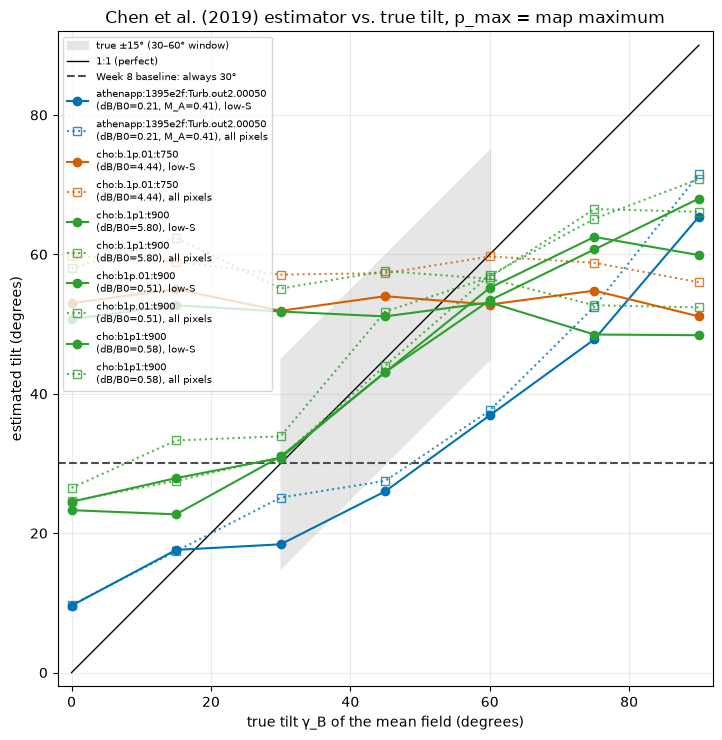

points plotted per run: {'athenapp:1395e2f:Turb.out2.00050': 7, 'cho:b.1p.01:t750': 7, 'cho:b.1p1:t900': 7, 'cho:b1p.01:t900': 7, 'cho:b1p1:t900': 7}


In [9]:
runs = [r for r in ok.run_id.unique()]
assert runs, "no run produced numbers: nothing to plot (check data_status in section 3)"
colour = {CATS_ID: "#d55e00", ATHENA_ID: "#0072b2"}
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.fill_between([30, 60], [15, 45], [45, 75], color="0.9", label="true ±15° (30–60° window)")
ax.plot([0, 90], [0, 90], "k-", lw=1, label="1:1 (perfect)")
ax.axhline(30, color="0.3", ls="--", lw=1.5, label="Week 8 baseline: always 30°")
for r in runs:
    d = ok[ok.run_id == r]
    ma = d.M_A.iloc[0]
    lab = f"{r}\n(dB/B0={d.dB_over_B0.iloc[0]:.2f}" + (f", M_A={ma:.2f})" if pd.notna(ma) else ")")
    ax.plot(d.gamma_B_true, d.gamma_obs_lowS, "o-", color=colour.get(r, "C2"), label=lab + ", low-S")
    ax.plot(d.gamma_B_true, d.gamma_obs, "s:", mfc="none", color=colour.get(r, "C2"), alpha=0.8, label=lab + ", all pixels")
ax.set_xlabel("true tilt γ_B of the mean field (degrees)")
ax.set_ylabel("estimated tilt (degrees)")
ax.set_xlim(-2, 92); ax.set_ylim(-2, 92); ax.set_aspect("equal")
ax.set_title("Chen et al. (2019) estimator vs. true tilt, p_max = map maximum")
ax.legend(fontsize=7.5, loc="upper left"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(PROJECT / "comparison_baseline_alexis.png", dpi=150); plt.show()
print("points plotted per run:", ok.groupby("run_id").size().to_dict())

### Quantitative comparison (true tilts 30–60°, the range my protocol grades)
`evaluate.grade` is the Week 8 rule: **median |error| < 15°** *and* **slope of estimate vs. truth > 0.5**.
The baseline's slope is 0 by construction, so it can never pass the tracking test.

In [10]:
rows = []
for r in runs:
    d = ok[ok.run_id == r]
    for label, col in (("estimator, low-S", "gamma_obs_lowS"), ("estimator, all pixels", "gamma_obs"), ("baseline (30°)", "baseline")):
        try:
            g = grade(d.gamma_B_true, d[col])
            rows.append({"run": r, "method": label, "n": g["n_maps"],
                         "median_signed_err": g["median_signed_err"], "median_abs_err": g["median_abs_err"],
                         "slope": g["slope"], "pass_abs_err<15": g["pass_abs_err"],
                         "pass_slope>0.5": g["pass_tracking"], "PASS": g["PASS"]})
        except ValueError as e:
            rows.append({"run": r, "method": label, "n": 0, "PASS": f"not graded ({e})"})
tab = pd.DataFrame(rows)
tab.round(2)

,run,method,n,median_signed_err,median_abs_err,slope,pass_abs_err<15,pass_slope>0.5,PASS
0,athenapp:1395e2f:Turb.out2.00050,"estimator, low-S",3,-19.0,19.0,0.62,False,True,False
1,athenapp:1395e2f:Turb.out2.00050,"estimator, all pixels",3,-17.5,17.5,0.42,False,False,False
2,athenapp:1395e2f:Turb.out2.00050,baseline (30°),3,-15.0,15.0,0.00,False,False,False
3,cho:b.1p.01:t750,"estimator, low-S",3,9.0,9.0,0.03,True,False,False
4,cho:b.1p.01:t750,"estimator, all pixels",3,12.3,12.3,0.09,True,False,False
5,cho:b.1p.01:t750,baseline (30°),3,-15.0,15.0,0.00,False,False,False
6,cho:b.1p1:t900,"estimator, low-S",3,6.1,6.9,0.04,True,False,False
7,cho:b.1p1:t900,"estimator, all pixels",3,12.6,12.6,0.05,True,False,False
8,cho:b.1p1:t900,baseline (30°),3,-15.0,15.0,0.00,False,False,False
9,cho:b1p.01:t900,"estimator, low-S",3,-1.9,1.9,0.75,True,True,True


## 5. Check against my Week 8 numbers

HW8's `physics_check_alexis.csv` holds the estimator's results for the four CATS runs (and two AREPO runs that are not in this pipeline), computed *before* the pipeline existed.
If the new ingestion path is correct, the pipeline must reproduce every CATS row (within the 0.5° tolerance of my protocol).

In [11]:
cands = [PROJECT / "hw8" / "physics_check_alexis.csv", PROJECT / "physics_check_alexis.csv"]
csv = next((c for c in cands if c.exists()), None)
if csv is None:
    print("physics_check_alexis.csv not found; copy it from the HW8 branch to compare.")
else:
    cols = ["run", "angle", "gamma_B_true", "gamma_obs", "gamma_obs_lowS"]
    old = pd.read_csv(csv)[cols]
    names = pd.read_sql("SELECT run_id, legacy_name AS run FROM datasets", con)
    new = ok.merge(names, on="run_id")[cols]
    cmp = old.merge(new, on=["run", "angle"], suffixes=("_hw8", "_pipeline"))
    if cmp.empty:
        print("no run is in both HW8 and the pipeline cache, so there is nothing to compare")
    else:
        cmp["diff_all"] = cmp.gamma_obs_pipeline - cmp.gamma_obs_hw8
        cmp["diff_lowS"] = cmp.gamma_obs_lowS_pipeline - cmp.gamma_obs_lowS_hw8
        print(cmp.round(2).to_string(index=False))
        worst = float(max(cmp.diff_all.abs().max(), cmp.diff_lowS.abs().max()))
        print(f"\n{len(cmp)} rows from {cmp.run.nunique()} runs; max |difference| (all pixels and low-S): {worst} deg",
              "→ AGREES (≤ 0.5°)" if worst <= 0.5 else "→ DIFFERS: investigate before trusting the pipeline")
        skipped = sorted(set(old.run) - set(cmp.run))
        if skipped:
            print("in HW8 but not in this pipeline:", ", ".join(skipped))


         run  angle  gamma_B_true_hw8  gamma_obs_hw8  gamma_obs_lowS_hw8  gamma_B_true_pipeline  gamma_obs_pipeline  gamma_obs_lowS_pipeline  diff_all  diff_lowS
   b1p1_t900     30              30.0           33.9                30.8                   30.0                33.9                     30.8       0.0        0.0
   b1p1_t900     45              45.0           51.8                43.1                   45.0                51.8                     43.1       0.0        0.0
   b1p1_t900     60              60.0           56.7                55.2                   60.0                56.7                     55.2       0.0        0.0
 b1p.01_t900     30              30.0           30.9                31.0                   30.0                30.9                     31.0       0.0        0.0
 b1p.01_t900     45              45.0           44.0                43.1                   45.0                44.0                     43.1       0.0        0.0
 b1p.01_t900     60         

## 5b. Why the Athena++ box fails

The Athena++ box is the most ordered run (dB/B0 = 0.21) and fails the grade in section 4 (low-S median error −19°). The table and figure below locate the cause. They are computed here from the same `.athdf` file the pipeline ingested, with p_max = map maximum.

* **`flattest_sightline`** is the smallest sky-projected tilt found in the map (0.5th percentile). **`p_max`** matches **`eq7_at_flattest`** (the polarization of a uniform field at that tilt), not **`eq7_at_tilt_0`** (0.158, what Chen et al. eq. 9 assumes p_max to be). So the brightest pixel is not "fully polarized", and the derived **`p0_derived`** falls below the true 0.15 as the tilt grows (0.054 at 60°).
* With the **true p0 = 0.15** (an oracle: a real observer does not know it) the 30–60° errors are −1.7°, −1.8° and +0.1°, so the tilt formula (eq. 10) and the maps are fine. The error comes from the p0 step (eq. 9). This is the effect Chen et al. (2019) describe in their Appendix A.
* The rows at 0° and 90° are also affected by the peak search being confined to 0–90° (the 0° row is off by +9.7° even with the true p0), so they are not evidence about p0.
* Not the cause: resolution (halving it changes the 30–60° estimates by under 2°) or the p_max rule (see `check_p0_athena_alexis.py`). `sweep_turbulence_alexis.py` shows the failure goes away as the box becomes less ordered.


,flattest_sightline,p_max,eq7_at_flattest,eq7_at_tilt_0,p0_derived,p0_true,lowS_est_derived_p0,lowS_est_true_p0,err_derived_p0,err_true_p0
true_tilt,,,,,,,,,,
0.0,2.746,0.156,0.157,0.158,0.148,0.15,9.6,9.7,9.6,9.7
15.0,7.684,0.151,0.155,0.158,0.144,0.15,17.6,20.6,2.6,5.6
30.0,22.166,0.133,0.132,0.158,0.127,0.15,18.4,28.3,-11.6,-1.7
45.0,35.929,0.098,0.098,0.158,0.095,0.15,26.0,43.2,-19.0,-1.8
60.0,51.132,0.055,0.057,0.158,0.054,0.15,36.9,60.1,-23.1,0.1
75.0,65.098,0.024,0.025,0.158,0.024,0.15,47.8,73.6,-27.2,-1.4
90.0,70.314,0.016,0.016,0.158,0.016,0.15,65.4,81.7,-24.6,-8.3


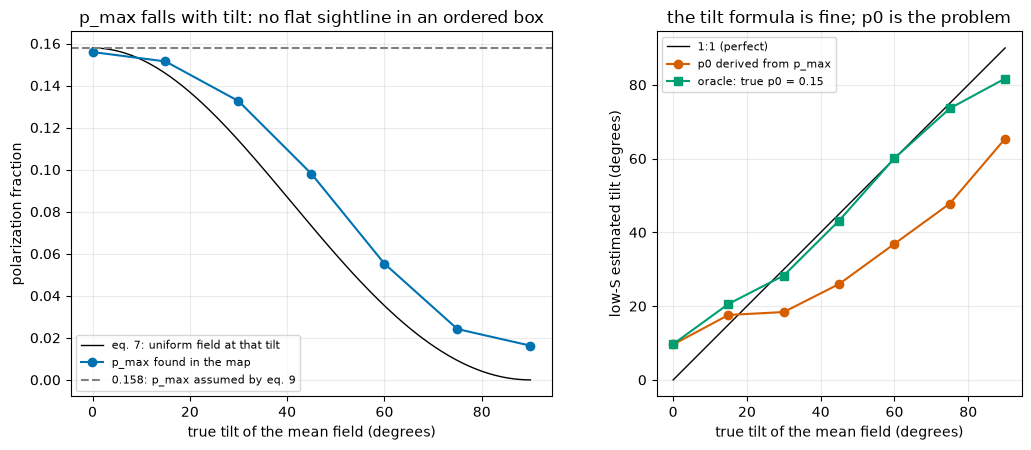

In [12]:
# 5b. Why does the Athena++ box fail?  (reads the same .athdf file the pipeline used; nothing is written to the cache)
import firstmap_b as fm
import rotate_maps as rm

ATHDF = PROJECT / "data" / "athena" / "Turb.out2.00050.athdf"
rho_a, B_a, vel_a, meta_a = pl.read_athdf(ATHDF)
fa, pa, mean_a = rm.choose_axes(B_a)
P0_TRUE = fm.P0_TRUE                                   # 0.15, the p0 put into the maps


def eq7(gamma_deg, p0=P0_TRUE):
    """Chen et al. (2019) eq. 7: polarization fraction of a uniform field tilted by gamma."""
    c = np.cos(np.radians(gamma_deg)) ** 2
    return p0 * c / (1 - p0 * (c - 2 / 3))


old_pct, fm.PMAX_PERCENTILE = fm.PMAX_PERCENTILE, 100.0          # p_max = map maximum, the project's rule
rows = []
for th in (0, 15, 30, 45, 60, 75, 90):
    N, Q, U, p, c = rm.rotated_maps(rho_a, B_a, th, fa, pa)
    t = rm.true_gamma(mean_a, th, fa, pa)
    r = fm.estimate_from_maps(Q, U, p, c, t, mask_border=True)
    flat = np.percentile(np.degrees(np.arccos(np.sqrt(np.clip(c, 0, 1)))), 0.5)
    rows.append({"true_tilt": t, "flattest_sightline": flat, "p_max": r["p_max"], "eq7_at_flattest": eq7(flat),
                 "eq7_at_tilt_0": eq7(0.0), "p0_derived": r["p0_derived"], "p0_true": P0_TRUE,
                 "lowS_est_derived_p0": r["gamma_obs_lowS"], "lowS_est_true_p0": r["gamma_obs_truep0_lowS"]})
fm.PMAX_PERCENTILE = old_pct
diag = pd.DataFrame(rows)
diag["err_derived_p0"] = diag.lowS_est_derived_p0 - diag.true_tilt
diag["err_true_p0"] = diag.lowS_est_true_p0 - diag.true_tilt
display(diag.round(3).set_index("true_tilt"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
g = np.linspace(0, 90, 200)
a1.plot(g, eq7(g), "k-", lw=1, label="eq. 7: uniform field at that tilt")
a1.plot(diag.true_tilt, diag.p_max, "o-", color="#0072b2", label="p_max found in the map")
a1.axhline(eq7(0), color="0.5", ls="--", label=f"{eq7(0):.3f}: p_max assumed by eq. 9")
a1.set_xlabel("true tilt of the mean field (degrees)"); a1.set_ylabel("polarization fraction")
a1.set_title("p_max falls with tilt: no flat sightline in an ordered box"); a1.legend(fontsize=8, loc="lower left"); a1.grid(alpha=0.25)
a2.plot([0, 90], [0, 90], "k-", lw=1, label="1:1 (perfect)")
a2.plot(diag.true_tilt, diag.lowS_est_derived_p0, "o-", color="#d55e00", label="p0 derived from p_max")
a2.plot(diag.true_tilt, diag.lowS_est_true_p0, "s-", color="#009e73", label="oracle: true p0 = 0.15")
a2.set_xlabel("true tilt of the mean field (degrees)"); a2.set_ylabel("low-S estimated tilt (degrees)")
a2.set_title("the tilt formula is fine; p0 is the problem"); a2.set_aspect("equal"); a2.legend(fontsize=8, loc="upper left"); a2.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(PROJECT / "athena_p0_diagnosis_alexis.png", dpi=150); plt.show()


## 6. What this shows, and the limits

All numbers below are for the low-S estimator with p_max = the map maximum, graded over true tilts of 30–60° (section 4), unless stated.

**Baseline comparison.** Only the two CATS runs with dB/B₀ ≈ 0.5 (`b1p.01_t900` and `b1p1_t900`) pass both of my tests: median |error| 1.9° and slope 0.75 and 0.81, against 15.0° and slope 0 for the always-30° baseline. The baseline's median |error| is exactly 15.0°, so it also fails the "< 15°" test, and with a constant guess it can never pass the slope test. The baseline wins at a true tilt of 30°, where its error is zero and every run's estimator is off by 0.8° to 21.9°. At 60° the estimator is closer to the truth than the baseline in all five runs; at 45° in four of five (the Athena++ box is off by −19° against the baseline's −15°).

**Regime: too turbulent.** The two super-Alfvénic CATS runs (`b.1p.01_t750`, dB/B₀ = 4.4, and `b.1p1_t900`, dB/B₀ = 5.8) return roughly 51–57° whatever the true tilt (slope 0.03 and 0.04). They pass the "< 15°" test only because the 30–60° window is centred on 45°, so a nearly constant ~52° guess is close to the truth there. The slope test is what shows they do not track the tilt. Chen et al. (2019) see the same compression toward ~45–55° in their most turbulent model L20 (45.4° at γ_B ≈ 30°, 50.5° at ≈ 60°; their Table A1), but L20 still rises with the tilt. The difference is not the polarization-angle dispersion, which is similar (median S = 4.2° and 6.3° at 0° here, 4.4° for L20 and 7.9° for Vela C in their Table 2; resolutions differ, so this is approximate). It is the 3D field: with dB/B₀ = 4.4–5.8 the mean field carries only 3–5% of the magnetic energy, and the density-weighted tilt γ_2D stays at 31–36° at every viewing angle, close to the 35.3° of an isotropic field. The mean-field tilt γ_B is then not something the polarization map can see.

**Regime: too ordered, and why (section 5b).** The Athena++ box (dB/B₀ = 0.21, M_A = 0.41) is the most ordered run and fails: median error −19° (all pixels −17.5°). The tilt formula is not the problem. With the true p₀ = 0.15 the errors at 30°, 45° and 60° are −1.7°, −1.8° and +0.1°. The problem is the p₀ derived from p_max (Chen et al. eq. 9). When a very ordered field is tilted, no sightline lies flat in the sky: the flattest sightline is at 22°, 36° and 51° for true tilts of 30°, 45° and 60°, and p_max (0.133, 0.098, 0.055) matches the polarization of a uniform field at that tilt, not the 0.158 that eq. 9 assumes. The derived p₀ is therefore too small (0.127, 0.095, 0.054 against 0.15) and every tilt comes out too low. This also breaks Chen et al.'s bound γ_obs ≥ γ_2D (γ_obs is the largest tilt consistent with p): here γ_obs, S<S̃ = 18°, 26°, 37° against γ_2D = 32°, 43°, 60°, which an underestimated p₀ explains and line-of-sight cancellation cannot. This is the effect described in Chen et al.'s Appendix A, and it is much larger here (36% of p₀ recovered at 60°) than in their least-perturbed model L1 (82%). I do not yet know why. A box with stronger density contrast, as in their colliding clouds, would test one explanation.

**Working window.** `sweep_turbulence_alexis.py` multiplies the turbulent field of this snapshot by k with the mean field fixed. The flattest sightline gets flatter, the derived p₀ rises (0.035 to 0.111) and the error at 60° shrinks (−60° to −6°); both tests pass only near dB/B₀ ≈ 0.4 (k = 2), and the estimates stop tracking the tilt above dB/B₀ ≈ 1. This matches the real runs (pass at 0.5, fail at 0.2 and at 4.4–5.8), but it changes the field of one snapshot with density and velocity fixed, so it is a probe and not a simulation.

**Limits.**
* One snapshot per run, and three graded tilts (30°, 45°, 60°), so slopes are noisy and values such as 0.50 are not sharp boundaries.
* The Athena++ box is 64³ against 256³ for CATS. Halving its resolution changes the 30–60° estimates by under 2°, and using the 99.5th-percentile p_max instead of the maximum does not fix the failure (`check_p0_athena_alexis.py`).
* The true-p₀ comparison uses information a real observer does not have; it shows where the error comes from, not a correction I can apply.
* CATS has no velocity cubes or field units, so M_s and M_A are missing for those runs (logged with the source URL, not guessed).
* CATS and my box are periodic driven-turbulence boxes; Chen et al. use shock-compressed colliding-cloud layers, so their numbers are a guide, not a like-for-like benchmark. Maps assume optically thin emission and uniform grain alignment, with no noise or beam.
* The two AREPO runs from Week 8 (gravity on) are not in this pipeline, so the gravity comparison is not done.
* The Athena++ output is not bit-identical across machines (compiler, CPU); the pipeline cache is bit-for-bit reproducible from the same files (section 1).

**Not done here.** Claude's own answers through the MCP server (Week 8 harness) are not included. The comparison above is the physics estimator against the baseline.
